In [3]:
import sys
sys.path.append("../scripts")
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

import sys

SCRIPTS_DIR = "/home/s2026aj05468/ML Assignment 2/Machine_Learning_Assignment2/scripts"
if SCRIPTS_DIR not in sys.path:
    sys.path.append(SCRIPTS_DIR)

from config import TRAIN_CSV, TEST_CSV, MODEL_DIR
print(TEST_CSV)
print(MODEL_DIR)

train = pd.read_csv(TRAIN_CSV)
X_train = train.drop(columns=["Class"])
y_train = train["Class"]

/home/s2026aj05468/ML Assignment/Machine_Learning_Assignment2/data/test_data.csv
/home/s2026aj05468/ML Assignment/Machine_Learning_Assignment2/model


In [2]:
for c in [0.01, 0.1, 1, 10, 100]:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(C=c, max_iter=1000)),
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="accuracy")
    print(f"C={c}: mean accuracy {scores.mean():.4f} (+/- {scores.std():.4f})")

C=0.01: mean accuracy 0.9188 (+/- 0.0020)
C=0.1: mean accuracy 0.9234 (+/- 0.0025)
C=1: mean accuracy 0.9240 (+/- 0.0024)
C=10: mean accuracy 0.9251 (+/- 0.0026)


KeyboardInterrupt: 

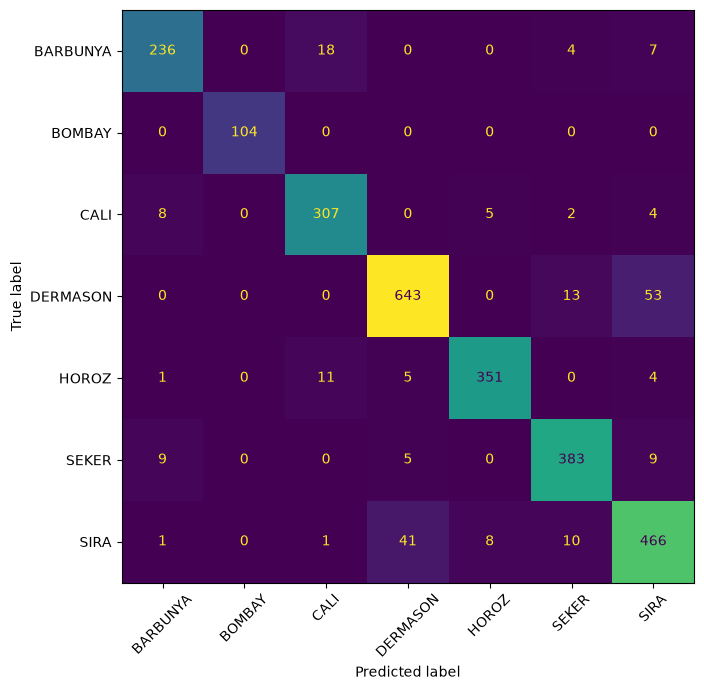

In [3]:
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from config import TEST_CSV, MODEL_DIR

test = pd.read_csv(TEST_CSV)
X_test = test.drop(columns=["Class"])
y_test = test["Class"]

model = joblib.load(MODEL_DIR / "logistic_regression.joblib")

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.show()

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate

for d in [3, 5, 8, 12, 20, None]:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    res = cross_validate(tree, X_train, y_train, cv=5, scoring="accuracy", return_train_score=True)
    print(f"max_depth={d}: train {res['train_score'].mean():.4f} | validation {res['test_score'].mean():.4f}")

max_depth=3: train 0.8017 | validation 0.7997
max_depth=5: train 0.9012 | validation 0.8877
max_depth=8: train 0.9488 | validation 0.9079
max_depth=12: train 0.9858 | validation 0.9014
max_depth=20: train 0.9991 | validation 0.8973
max_depth=None: train 1.0000 | validation 0.8972


In [5]:
for d in [6, 7, 8, 9, 10]:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    res = cross_validate(tree, X_train, y_train, cv=5, scoring="accuracy", return_train_score=True)
    print(f"max_depth={d}: train {res['train_score'].mean():.4f} | validation {res['test_score'].mean():.4f}")

max_depth=6: train 0.9191 | validation 0.9008
max_depth=7: train 0.9352 | validation 0.9058
max_depth=8: train 0.9488 | validation 0.9079
max_depth=9: train 0.9610 | validation 0.9088
max_depth=10: train 0.9706 | validation 0.9057


In [3]:
from sklearn.neighbors import KNeighborsClassifier

# with scaling
for k in [1, 3, 5, 11, 21, 31]:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=k)),
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="accuracy")
    print(f"scaled   k={k}: {scores.mean():.4f} (+/- {scores.std():.4f})")

scaled   k=1: 0.9047 (+/- 0.0020)
scaled   k=3: 0.9192 (+/- 0.0011)
scaled   k=5: 0.9215 (+/- 0.0016)
scaled   k=11: 0.9238 (+/- 0.0024)
scaled   k=21: 0.9250 (+/- 0.0023)
scaled   k=31: 0.9241 (+/- 0.0013)


In [4]:
# without scaling, for comparison
for k in [5, 11, 21]:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train, y_train, cv=5, scoring="accuracy")
    print(f"unscaled k={k}: {scores.mean():.4f} (+/- {scores.std():.4f})")

unscaled k=5: 0.7167 (+/- 0.0069)
unscaled k=11: 0.6969 (+/- 0.0120)
unscaled k=21: 0.6793 (+/- 0.0071)


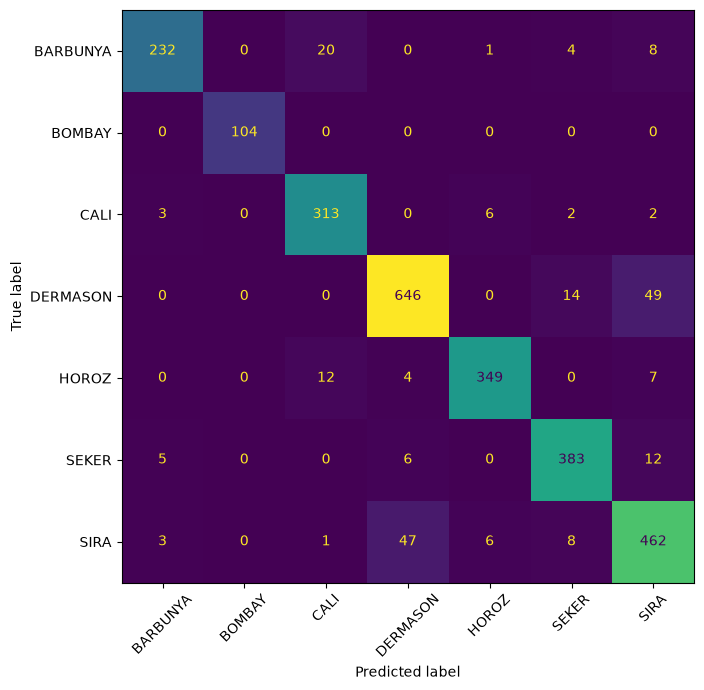

In [4]:
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from config import TEST_CSV, MODEL_DIR

test = pd.read_csv(TEST_CSV)
X_test = test.drop(columns=["Class"])
y_test = test["Class"]

model = joblib.load(MODEL_DIR / "knn.joblib")

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.show()

In [5]:
import numpy as np
from sklearn.naive_bayes import GaussianNB

for vs in np.logspace(-11, -1, 6):
    nb = GaussianNB(var_smoothing=vs)
    scores = cross_val_score(nb, X_train, y_train, cv=5, scoring="accuracy")
    print(f"var_smoothing={vs:.0e}: {scores.mean():.4f} (+/- {scores.std():.4f})")

var_smoothing=1e-11: 0.8534 (+/- 0.0056)
var_smoothing=1e-09: 0.7632 (+/- 0.0082)
var_smoothing=1e-07: 0.7369 (+/- 0.0062)
var_smoothing=1e-05: 0.6454 (+/- 0.0127)
var_smoothing=1e-03: 0.6315 (+/- 0.0141)
var_smoothing=1e-01: 0.6200 (+/- 0.0045)


In [6]:
size_cols = ["Area", "Perimeter", "ConvexArea", "EquivDiameter"]
X_reduced = X_train.drop(columns=size_cols)

for name, data in [("all features", X_train), ("without size columns", X_reduced)]:
    scores = cross_val_score(GaussianNB(), data, y_train, cv=5, scoring="accuracy")
    print(f"{name}: {scores.mean():.4f} (+/- {scores.std():.4f})")

all features: 0.7632 (+/- 0.0082)
without size columns: 0.8828 (+/- 0.0043)


In [7]:
# 1. push the grid lower, unscaled
for vs in [1e-15, 1e-13, 1e-12, 1e-11, 1e-10]:
    nb = GaussianNB(var_smoothing=vs)
    scores = cross_val_score(nb, X_train, y_train, cv=5, scoring="accuracy")
    print(f"unscaled var_smoothing={vs:.0e}: {scores.mean():.4f} (+/- {scores.std():.4f})")

unscaled var_smoothing=1e-15: 0.8984 (+/- 0.0034)
unscaled var_smoothing=1e-13: 0.8922 (+/- 0.0043)
unscaled var_smoothing=1e-12: 0.8854 (+/- 0.0046)
unscaled var_smoothing=1e-11: 0.8534 (+/- 0.0056)
unscaled var_smoothing=1e-10: 0.7870 (+/- 0.0099)


In [8]:
# 2. same model with the scaler in front
for vs in [1e-11, 1e-9, 1e-7, 1e-5]:
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", GaussianNB(var_smoothing=vs))])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="accuracy")
    print(f"scaled   var_smoothing={vs:.0e}: {scores.mean():.4f} (+/- {scores.std():.4f})")

scaled   var_smoothing=1e-11: 0.8964 (+/- 0.0034)
scaled   var_smoothing=1e-09: 0.8964 (+/- 0.0034)
scaled   var_smoothing=1e-07: 0.8964 (+/- 0.0034)
scaled   var_smoothing=1e-05: 0.8964 (+/- 0.0034)


In [9]:
# 3. redo the size-column comparison with smoothing taken out of the picture
for name, data in [("all features", X_train), ("without size columns", X_reduced)]:
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", GaussianNB(var_smoothing=1e-11))])
    scores = cross_val_score(pipe, data, y_train, cv=5, scoring="accuracy")
    print(f"scaled, 1e-11, {name}: {scores.mean():.4f} (+/- {scores.std():.4f})")

scaled, 1e-11, all features: 0.8964 (+/- 0.0034)
scaled, 1e-11, without size columns: 0.8931 (+/- 0.0031)


In [10]:
from sklearn.svm import SVC

for c in [0.1, 1, 10, 100]:
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", SVC(kernel="rbf", C=c))])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="accuracy")
    print(f"rbf C={c}: {scores.mean():.4f} (+/- {scores.std():.4f})")

rbf C=0.1: 0.9246 (+/- 0.0020)
rbf C=1: 0.9319 (+/- 0.0035)
rbf C=10: 0.9325 (+/- 0.0035)
rbf C=100: 0.9326 (+/- 0.0022)


In [11]:
pipe = Pipeline([("scaler", StandardScaler()), ("clf", SVC(kernel="linear", C=1))])
scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="accuracy")
print(f"linear C=1: {scores.mean():.4f} (+/- {scores.std():.4f})")

linear C=1: 0.9271 (+/- 0.0031)


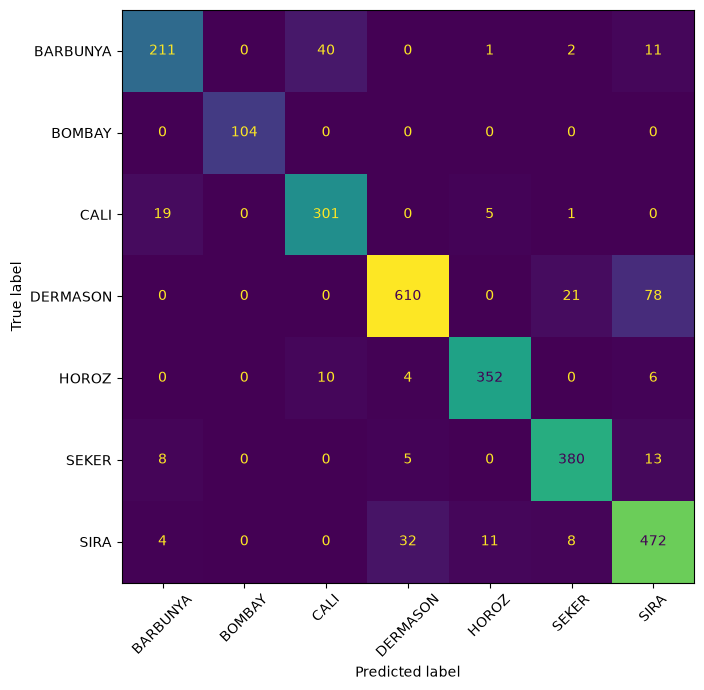

In [12]:
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from config import TEST_CSV, MODEL_DIR

test = pd.read_csv(TEST_CSV)
X_test = test.drop(columns=["Class"])
y_test = test["Class"]

model = joblib.load(MODEL_DIR / "naive_bayes.joblib")

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.show()

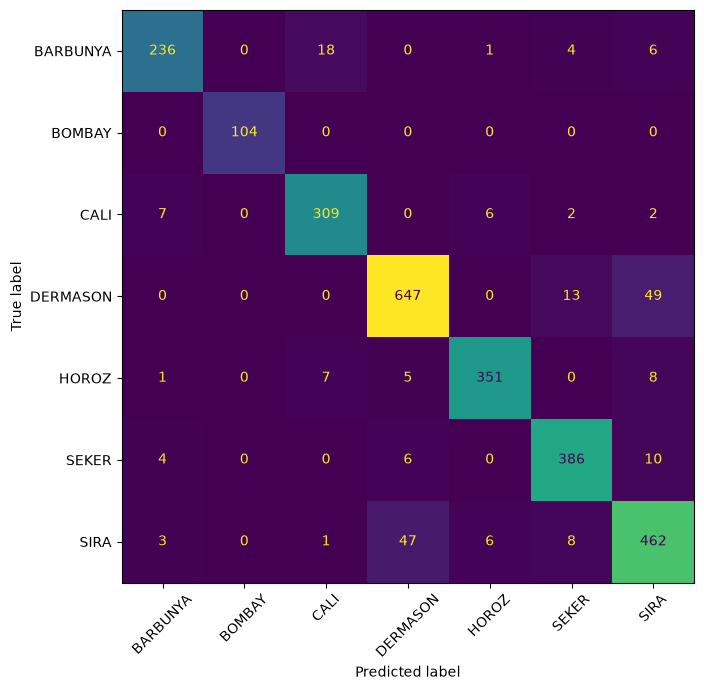

In [13]:
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from config import TEST_CSV, MODEL_DIR

test = pd.read_csv(TEST_CSV)
X_test = test.drop(columns=["Class"])
y_test = test["Class"]

model = joblib.load(MODEL_DIR / "svm.joblib")

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.show()

In [14]:
from sklearn.metrics import classification_report

model = joblib.load(MODEL_DIR / "svm.joblib")
print(classification_report(y_test, model.predict(X_test), digits=3))

              precision    recall  f1-score   support

    BARBUNYA      0.940     0.891     0.915       265
      BOMBAY      1.000     1.000     1.000       104
        CALI      0.922     0.948     0.935       326
    DERMASON      0.918     0.913     0.915       709
       HOROZ      0.964     0.944     0.954       372
       SEKER      0.935     0.951     0.943       406
        SIRA      0.860     0.877     0.868       527

    accuracy                          0.921      2709
   macro avg      0.934     0.932     0.933      2709
weighted avg      0.921     0.921     0.921      2709



In [17]:
import joblib
from sklearn.metrics import classification_report

model = joblib.load(MODEL_DIR / "svm.joblib")
print(classification_report(y_test, model.predict(X_test), digits=3))

              precision    recall  f1-score   support

    BARBUNYA      0.940     0.891     0.915       265
      BOMBAY      1.000     1.000     1.000       104
        CALI      0.922     0.948     0.935       326
    DERMASON      0.918     0.913     0.915       709
       HOROZ      0.964     0.944     0.954       372
       SEKER      0.935     0.951     0.943       406
        SIRA      0.860     0.877     0.868       527

    accuracy                          0.921      2709
   macro avg      0.934     0.932     0.933      2709
weighted avg      0.921     0.921     0.921      2709



In [16]:
test = pd.read_csv(TEST_CSV)
X_test = test.drop(columns=["Class"])
y_test = test["Class"]

In [18]:
import sys

SCRIPTS_DIR = "/home/s2026aj05468/ML Assignment 2/Machine_Learning_Assignment2/scripts"
if SCRIPTS_DIR not in sys.path:
    sys.path.append(SCRIPTS_DIR)

import pandas as pd
import joblib
from sklearn.metrics import classification_report
from config import TEST_CSV, MODEL_DIR

test = pd.read_csv(TEST_CSV)
X_test = test.drop(columns=["Class"])
y_test = test["Class"]

model = joblib.load(MODEL_DIR / "svm.joblib")
print(classification_report(y_test, model.predict(X_test), digits=3))

              precision    recall  f1-score   support

    BARBUNYA      0.940     0.891     0.915       265
      BOMBAY      1.000     1.000     1.000       104
        CALI      0.922     0.948     0.935       326
    DERMASON      0.918     0.913     0.915       709
       HOROZ      0.964     0.944     0.954       372
       SEKER      0.935     0.951     0.943       406
        SIRA      0.860     0.877     0.868       527

    accuracy                          0.921      2709
   macro avg      0.934     0.932     0.933      2709
weighted avg      0.921     0.921     0.921      2709

